# INF201 - Deliverable 1

## Task 1: Temperatures 

In [3]:
import requests
import pandas as pd
import matplotlib.pyplot as plt

In [27]:
with open('client_id.txt', 'r') as file:
    my_id = file.read().strip()

parameters = {
    "sources": "SN17850", 
    "elements": "mean(air_temperature P1D)", 
    "referencetime": "2025-01-01/2026-01-01",
    "timeoffsets": "default",
    "levels": "default"
}

url = "https://frost.met.no/observations/v0.jsonld"

response = requests.get(
    url,
    params=parameters,
    auth=(my_id, "")
)

Exploring the API response

Before processing the data, we inspected the JSON response using data.keys() and observations[0] to understand its structure. We found that the response contains a list of dictionaries, where each dictionary represents a date and contains a nested list of temperature measurements.

We also discovered that the API returned two measurements with different time offsets (PT0H and PT6H). This needs to be considered when selecting the temperature data.

Finally, we checked the first and last dates and adjusted the requested interval to include all 365 days of 2025.

In [28]:
rows = []

for day in observations:
    date = day["referenceTime"]

    for measurement in day["observations"]:
        if measurement["timeOffset"] == "PT0H":
            temperature = measurement["value"]

            rows.append({
                "date": date,
                "temperature": temperature
            })

df = pd.DataFrame(rows)
df["date"] = pd.to_datetime(df["date"])

In [29]:
statistics = df["temperature"].agg(["mean", "median", "min", "max"])

statistics_table = statistics.to_frame(name="Temperature (°C)").round(2)
statistics_table

,Temperature (°C)
mean,7.87
median,8.30
min,-15.50
max,23.70


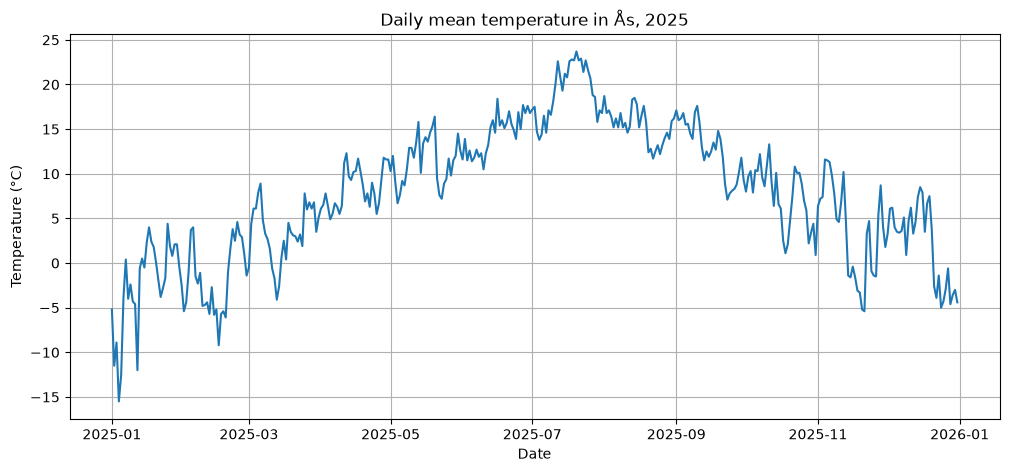

In [30]:
plt.figure(figsize=(12, 5))
plt.plot(df["date"], df["temperature"])

plt.xlabel("Date")
plt.ylabel("Temperature (°C)")
plt.title("Daily mean temperature in Ås, 2025")
plt.grid(True)
plt.show()

## Task 5

In [ ]:
def moving_average(temperatures):
    average = temperatures.rolling(window=7).mean()
    return average
